# Can contract groups help predict mispricing?

Becker finds systematic mispricing across Kalshi's dataset, despite good overall calibration. We extend this by asking whether finer groups of similar contracts help predict pricing errors on held-out events.

We compare three shared ridge models: **price only (pooled), price + structural family, and price + family + NLP cluster**. Pooled is the main modeling baseline; the unchanged market price is a separate benchmark with no fitted correction.

Run the cells in order using the project environment. DuckDB summarizes the roughly 65 million trades before modeling. All code is included here; figures and tables go to `output/extension_notebook_simple/`.

## 1. Data and splits

Master CSVs provide trades and outcomes; split CSVs define training, validation, and test events. We preserve these splits and check that contracts and event IDs do not cross them.

Only training outcomes fit the models. Settings are fixed, and validation/test scores are reported separately. These are event-based splits, not chronological forecasts or predictions made 72 hours before settlement.

In [214]:
from __future__ import annotations

import hashlib
import json
import re
import time
from importlib.metadata import version
from pathlib import Path
from types import SimpleNamespace

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap, LogNorm, TwoSlopeNorm
from scipy import sparse
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler, normalize
from threadpoolctl import threadpool_limits

SEED = 340
ALPHA = 10.0  # Fixed regularization; no tuning grid.
BOOTSTRAP = 2000
GROUPING = SimpleNamespace(
    fit_limit=20000,
    family_fit_limit=1000,
    distance=0.35,
    min_similarity=0.75,
    min_contracts=20,
    min_events=10,
)

ROOT = None
for directory in [Path.cwd(), *Path.cwd().parents]:
    if (directory / "data/kalshi_recent_year_csv").is_dir():
        ROOT = directory
        break
if ROOT is None:
    raise FileNotFoundError(
        "Run this notebook from the repository or one of its subdirectories.",
    )
DATA = ROOT / "data/kalshi_recent_year_csv"
OUTPUT = ROOT / "output/extension_notebook_simple"
OUTPUT.mkdir(parents=True, exist_ok=True)
required = [DATA / f"master/{name}.csv" for name in ["markets", "trades"]] + [
    DATA / f"split/{split}/markets.csv" for split in ["train", "validation", "test"]
]
for path in required:
    if not path.is_file():
        raise FileNotFoundError(path)
(OUTPUT / "run_manifest.json").write_text(json.dumps({"completed": False}) + "\n")
started = time.time()
# Slide palette: navy text, mint structural groups, lavender NLP groups.
PALETTE = {
    "navy": "#18163F",
    "mint": "#D9FBEA",
    "mint_dark": "#3D9F83",
    "lavender": "#BFC5FF",
    "lavender_dark": "#858DD5",
    "lavender_light": "#DFE3FF",
    "gray_light": "#F2F2F2",
    "gray": "#C7C8D1",
    "gray_dark": "#777786",
}
COLORS = {
    "Market price": PALETTE["gray_dark"],
    "Pooled": PALETTE["navy"],
    "Structural": PALETTE["mint_dark"],
    "Structural + NLP": PALETTE["lavender_dark"],
}
MODEL_FILLS = {
    "Pooled": PALETTE["navy"],
    "Structural": PALETTE["mint"],
    "Structural + NLP": PALETTE["lavender"],
}
STATUS_COLORS = {
    "assigned": PALETTE["mint"],
    "distant": PALETTE["lavender_dark"],
    "insufficient_training_support": PALETTE["gray"],
    "unseen_family": PALETTE["lavender_light"],
}
# Distinct colors for the cluster plot; other figures use the slide palette.
CLUSTER_COLORS = [
    PALETTE["navy"],
    PALETTE["mint_dark"],
    PALETTE["lavender_dark"],
    "#D77967",  # Muted coral.
    "#3F8DB8",  # Blue.
    "#BC9636",  # Gold.
]
COUNT_CMAP = LinearSegmentedColormap.from_list(
    "slide_counts",
    [PALETTE["gray_light"], PALETTE["lavender_light"], PALETTE["lavender"], PALETTE["navy"]],
)
DEVIATION_CMAP = LinearSegmentedColormap.from_list(
    "slide_deviations",
    [PALETTE["mint_dark"], PALETTE["mint"], "#FFFFFF", PALETTE["lavender"], PALETTE["navy"]],
)
COUNT_CMAP.set_bad("white")
DEVIATION_CMAP.set_bad(PALETTE["gray_light"])

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "font.size": 10,
        "axes.titleweight": "bold",
        "text.color": PALETTE["navy"],
        "axes.labelcolor": PALETTE["navy"],
        "axes.titlecolor": PALETTE["navy"],
        "axes.edgecolor": PALETTE["navy"],
        "xtick.color": PALETTE["navy"],
        "ytick.color": PALETTE["navy"],
        "axes.spines.top": False,
        "axes.spines.right": False,
        "lines.linewidth": 2,
        "lines.markeredgewidth": 0.4,
        "lines.markeredgecolor": PALETTE["navy"],
        "legend.facecolor": "white",
        "legend.edgecolor": PALETTE["gray"],
    },
)

SPLITS = ["train", "validation", "test"]


def show_figure(name: str) -> None:
    """Display a figure in the story and export the same figure for the paper."""
    plt.gcf().tight_layout()
    plt.gcf().savefig(OUTPUT / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

## 2. Structural families

Similar wording can describe different events: “above 80” might refer to temperature or a player's score. We first group contracts by **domain / underlying subject / proposition structure**, such as `crypto/BTC/above`.

Rules use titles, YES subtitles, and series codes, never prices or outcomes. Unrecognized attributes remain `unknown`, usually with a series-based fallback. We keep binary contracts with titles and event IDs and exclude MVE combination prefixes.

In [215]:
NUMBER = r"-?\d[\d,]*(?:\.\d+)?"


def extract_attributes(row: dict) -> dict:
    """Infer a structural family from wording and series, without prices or outcomes."""
    title = row.get("title", "") or ""
    subtitle = row.get("yes_sub_title", "") or ""
    text = f"{title} {subtitle}".strip()
    lower = text.lower()
    series = (row.get("event_ticker", "") or "").split("-")[0].removeprefix("KX")
    domain, underlying = "unknown", series or "unknown"
    for keyword, name in [
        ("bitcoin", "BTC"),
        ("ethereum", "ETH"),
        ("dogecoin", "DOGE"),
    ]:
        if keyword in lower:
            domain, underlying = "crypto", name
            break
    if "temp" in lower and ("high" in lower or "low" in lower):
        domain = "weather"
        # Preserve station/measurement identity rather than pooling different cities.
        underlying = series
    elif "s&p 500" in lower or "nasdaq" in lower:
        domain, underlying = "equities", "SP500" if "s&p 500" in lower else "NASDAQ100"
    elif re.match(r"(?:NFL|NBA|NCAA|MLB|NHL|WNBA|ATP|WTA|PGA)", series):
        domain = "sports"
        underlying = re.match(r"NCAAMB|NCAAF|WNBA|NFL|NBA|MLB|NHL|ATP|WTA|PGA", series)
        underlying = underlying.group() if underlying else series
    elif "MENTION" in series:
        domain = "mentions"

    # Prefer the affirmative subtitle: it often contains the actual proposition.
    proposition = (subtitle or title).lower()
    if "wins by" in lower:
        structure = "spread"
    elif "total points" in lower or "points scored" in lower:
        structure = "total"
    elif re.search(rf"{NUMBER}\s*°?\s*(?:to|–|—)\s*\$?{NUMBER}", proposition):
        structure = "interval"
    elif re.search(r"\b(?:above|over|exceed|greater|at least)\b|>|\d\+", proposition):
        structure = "above"
    elif re.search(r"\b(?:below|under|less|at most)\b|<", proposition):
        structure = "below"
    elif "winner" in lower or re.search(r"\bwin\b", lower):
        structure = "winner"
    else:
        structure = "unknown"
    # Do not pool distinct player-prop mechanisms just because they share a sport.
    if structure == "unknown" or (domain == "sports" and structure in {"above", "below"}):
        underlying = series or "unknown"
    attributes = {
        "series": series,
        "domain": domain,
        "underlying": underlying,
        "structure": structure,
    }
    attributes.update(family=f"{domain}/{underlying}/{structure}", text=text)
    return attributes

In [216]:
COLUMNS = [
    "ticker",
    "event_ticker",
    "market_type",
    "title",
    "yes_sub_title",
    "open_time",
    "close_time",
]


def load_contracts(root: Path) -> tuple[pd.DataFrame, dict]:
    """Read only CSV metadata and preserve supplied event-disjoint splits."""
    frames, counts = [], {}
    for split in ("train", "validation", "test"):
        path = root / "split" / split / "markets.csv"
        frame = pd.read_csv(
            path,
            usecols=COLUMNS,
            dtype=str,
            keep_default_na=False,
        )
        counts[split] = {"input": len(frame)}
        valid = (
            frame.market_type.eq("binary")
            & ~frame.ticker.str.startswith(("KXMVE", "MVE"))
            & frame.title.str.strip().ne("")
            & frame.event_ticker.str.strip().ne("")
        )
        frame = frame[valid].copy()
        counts[split]["retained"] = len(frame)
        frame["split"] = split
        frames.append(frame)
    contracts = pd.concat(frames, ignore_index=True)
    if contracts.ticker.duplicated().any():
        raise ValueError("Duplicate tickers in supplied splits")
    if contracts.groupby("event_ticker").split.nunique().gt(1).any():
        raise ValueError("Event IDs overlap supplied splits")
    attrs = pd.DataFrame(
        [extract_attributes(row) for row in contracts.to_dict("records")],
    )
    return pd.concat([contracts, attrs], axis=1), counts


def stable_sample(frame: pd.DataFrame, limit: int) -> pd.DataFrame:
    keys = frame.ticker.map(
        lambda value: hashlib.sha256(f"{SEED}:{value}".encode()).hexdigest(),
    )
    return frame.loc[keys.sort_values().index[:limit]]

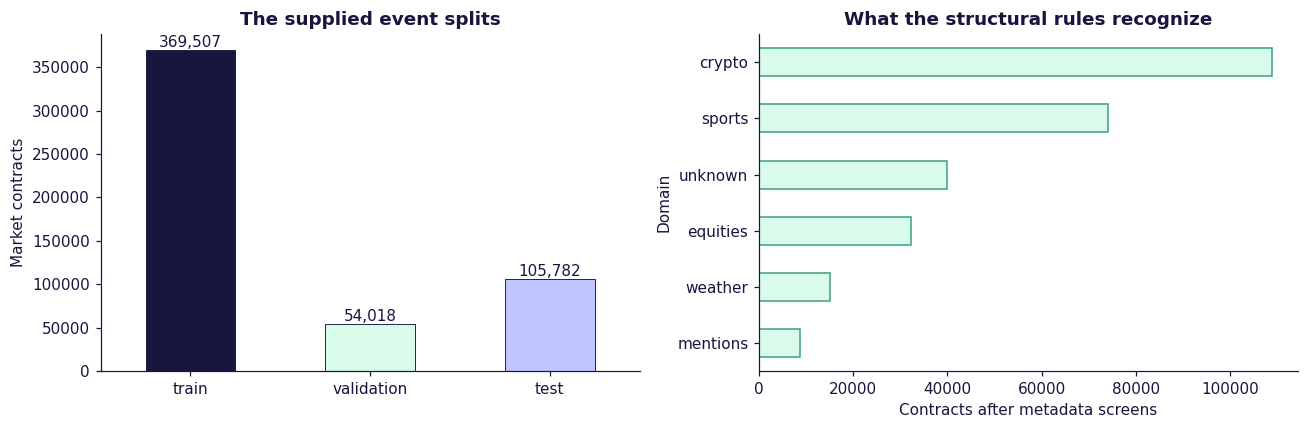

,input,structurally_eligible
train,369507,194378
validation,54018,28271
test,105782,56187


,title,yes_sub_title,family
0,Sacramento St. at UCLA Winner?,UCLA,sports/NCAAMB/winner
1,Sacramento St. at UCLA Winner?,Sacramento St.,sports/NCAAMB/winner
2,Northwestern St. at San Francisco Winner?,San Francisco,sports/NCAAMB/winner
3,Northwestern St. at San Francisco Winner?,Northwestern St.,sports/NCAAMB/winner
4,Idaho St. at Santa Clara Winner?,Santa Clara,sports/NCAAMB/winner
5,Idaho St. at Santa Clara Winner?,Idaho St.,sports/NCAAMB/winner


In [217]:
contracts, attrition = load_contracts(DATA)
input_counts = pd.Series({s: attrition[s]["input"] for s in SPLITS})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
input_counts.plot.bar(
    ax=axes[0],
    color=[PALETTE["navy"], PALETTE["mint"], PALETTE["lavender"]],
    edgecolor=PALETTE["navy"],
    linewidth=0.6,
    rot=0,
)
axes[0].set(
    title="The supplied event splits",
    ylabel="Market contracts",
    xlabel="",
)
for i, value in enumerate(input_counts):
    axes[0].text(
        i,
        value,
        f"{value:,}",
        ha="center",
        va="bottom",
    )
contracts.domain.value_counts().sort_values().plot.barh(
    ax=axes[1], color=PALETTE["mint"], edgecolor=PALETTE["mint_dark"]
)
axes[1].set(
    title="What the structural rules recognize",
    xlabel="Contracts after metadata screens",
    ylabel="Domain",
)

show_figure("01_data_landscape")
display(pd.DataFrame(attrition).T.rename(columns={"retained": "structurally_eligible"}))
display(contracts[["title", "yes_sub_title", "family"]].head(6))

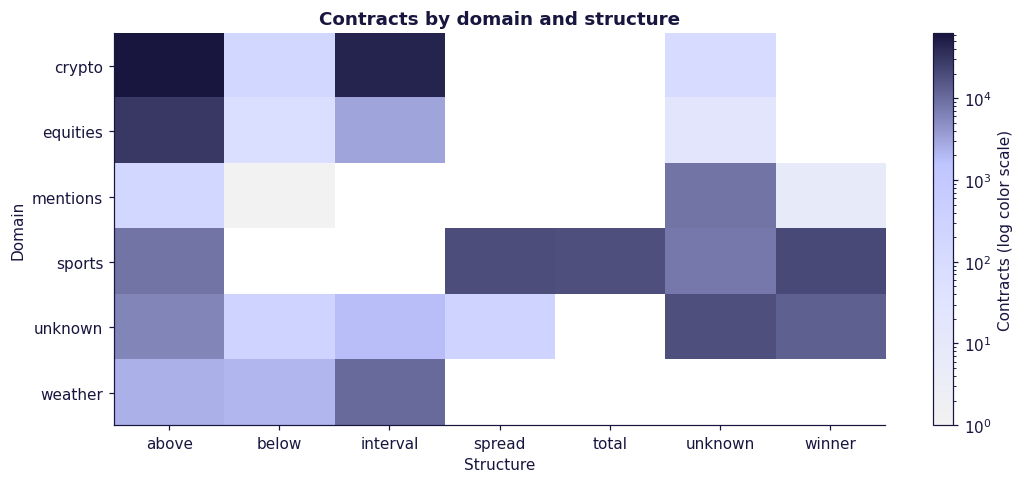

In [218]:
structure_counts = pd.crosstab(contracts.domain, contracts.structure)

fig, ax = plt.subplots(figsize=(10, 4.5))
image = ax.imshow(
    np.ma.masked_equal(structure_counts.to_numpy(), 0),
    norm=LogNorm(vmin=1, vmax=max(2, structure_counts.to_numpy().max())),
    cmap=COUNT_CMAP,
    aspect="auto",
)
ax.set_xticks(range(len(structure_counts.columns)), structure_counts.columns)
ax.set_yticks(range(len(structure_counts.index)), structure_counts.index)
ax.set(
    title="Contracts by domain and structure",
    xlabel="Structure",
    ylabel="Domain",
)
plt.colorbar(image, ax=ax, label="Contracts (log color scale)")

show_figure("02_structural_map")

**Read the figures:** bars show contract counts by split and recognized domain. In the heatmap, darker navy means more contracts; the color scale is logarithmic and blank cells contain none. Each domain includes several proposition types, motivating families more specific than topic alone.

## 3. Refine families using text

We learn text groups from training contracts only:

- **TF-IDF:** words and two-word phrases; up to 20,000 terms from a fixed sample of 20,000 contracts.
- **LSA:** reduce the text vectors to at most 64 dimensions and normalize them.
- **Hierarchical clustering:** average-linkage cosine distance, cutoff 0.35, using up to 1,000 training contracts per family.
- **Assignment:** match to frozen cluster centers at similarity ≥0.75, requiring 20 training contracts from 10 events per cluster.

Validation/test text uses the frozen representation and assignment rules. Unsupported or distant contracts stay unassigned. Cluster IDs are category labels, not numerical scores.

In [219]:
def embed(frame: pd.DataFrame, args) -> np.ndarray:
    """Fit TF-IDF and LSA on the training sample, then transform every split."""
    fit = stable_sample(frame[frame.split.eq("train")], args.fit_limit)
    vectorizer = TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=20000,
        sublinear_tf=True,
    )
    matrix = vectorizer.fit_transform(fit.text)
    dimensions = min(64, matrix.shape[1] - 1, matrix.shape[0] - 1)
    if dimensions < 2:
        raise ValueError("Insufficient training vocabulary/contracts for LSA")
    svd = TruncatedSVD(n_components=dimensions, random_state=SEED).fit(matrix)
    # Transform in batches to limit memory use.
    batches = []
    for start in range(0, len(frame), 10000):
        text_batch = frame.text.iloc[start : start + 10000]
        word_vectors = vectorizer.transform(text_batch)
        reduced_vectors = svd.transform(word_vectors)
        batches.append(normalize(reduced_vectors).astype("float32"))

    return np.vstack(batches)


def group_contracts(frame: pd.DataFrame, vectors: np.ndarray, args) -> pd.DataFrame:
    """Learn groups on train, then assign contracts using frozen centers and support."""
    result = frame.assign(
        cluster="",
        status="unseen_family",
        similarity=np.nan,
    )
    for family, members in frame.groupby("family", sort=True):
        train = members[members.split.eq("train")]
        if train.empty:
            continue
        sample = stable_sample(train, args.family_fit_limit)
        ix = sample.index.to_numpy()
        ix = ix[np.linalg.norm(vectors[ix], axis=1) > 0]
        result.loc[members.index, "status"] = "insufficient_training_support"
        if len(ix) < 2:
            continue
        labels = AgglomerativeClustering(
            n_clusters=None,
            distance_threshold=args.distance,
            metric="cosine",
            linkage="average",
        ).fit_predict(
            vectors[ix],
        )
        centers = []
        for label in np.unique(labels):
            cluster_vectors = vectors[ix[labels == label]]
            centers.append(cluster_vectors.mean(axis=0))
        centers = normalize(np.vstack(centers))
        train_ids = train.index.to_numpy()
        # Determine support using all training contracts, never validation/test counts.
        train_scores = vectors[train_ids] @ centers.T
        nearest = train_scores.argmax(axis=1)
        close = train_scores.max(axis=1) >= args.min_similarity
        supported = []
        for label in range(len(centers)):
            peers = train.iloc[np.flatnonzero((nearest == label) & close)]
            if len(peers) >= args.min_contracts and peers.event_ticker.nunique() >= args.min_events:
                supported.append(label)
        ids = members.index.to_numpy()
        scores = vectors[ids] @ centers.T
        nearest = scores.argmax(axis=1)
        similarity = scores.max(axis=1)
        result.loc[ids, "similarity"] = similarity
        result.loc[ids, "status"] = "distant"
        for label in range(len(centers)):
            mask = (nearest == label) & (similarity >= args.min_similarity)
            chosen = ids[mask]
            if label in supported:
                result.loc[chosen, "cluster"] = f"{family}/{label:03d}"
                result.loc[chosen, "status"] = "assigned"
            else:
                result.loc[chosen, "status"] = "insufficient_training_support"
    return result

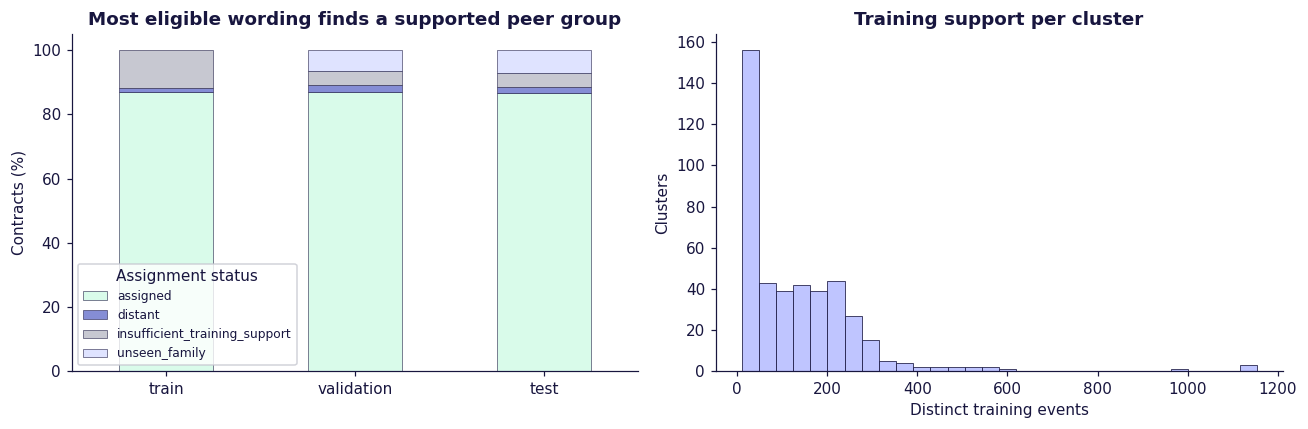

status,assigned,distant,insufficient_training_support,unseen_family
split,,,,
train,169195,2189,22994,0
validation,24547,629,1243,1852
test,48744,1087,2291,4065


In [220]:
with threadpool_limits(limits=2):
    vectors = embed(contracts, GROUPING)
    assignments = group_contracts(contracts, vectors, GROUPING)
ASSIGNMENTS = OUTPUT / "assignments.csv"
assignments.to_csv(ASSIGNMENTS, index=False)
coverage = (
    assignments.groupby(["split", "status"])
    .size()
    .unstack(
        fill_value=0,
    )
    .reindex(
        SPLITS,
    )
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
coverage_pct = coverage.div(coverage.sum(axis=1), axis=0).mul(100)
coverage_pct.plot.bar(
    stacked=True,
    ax=axes[0],
    rot=0,
    color=[STATUS_COLORS[status] for status in coverage.columns],
    edgecolor=PALETTE["navy"],
    linewidth=0.35,
)
axes[0].set(
    title="Most eligible wording finds a supported peer group",
    ylabel="Contracts (%)",
    xlabel="",
)
axes[0].legend(title="Assignment status", fontsize=8)
training_groups = (
    assignments.query("split == 'train' and status == 'assigned'")
    .groupby(
        "cluster",
    )
    .agg(
        contracts=("ticker", "nunique"),
        events=("event_ticker", "nunique"),
    )
)
axes[1].hist(
    training_groups.events,
    bins=30,
    color=PALETTE["lavender"],
    edgecolor=PALETTE["navy"],
    linewidth=0.5,
)
axes[1].set(
    title="Training support per cluster",
    xlabel="Distinct training events",
    ylabel="Clusters",
)

show_figure("03_group_coverage")
display(coverage)
training_groups.to_csv(OUTPUT / "clustering_training_support.csv")

### Inspect the groups

The coverage bars show assigned and rejected shares. The histogram counts distinct training events per cluster: many trades from one event do not provide many independent outcomes.

Below, we inspect the largest assigned training family. Colors show its six largest clusters; gray shows the rest. PCA projects the text vectors into two dimensions **for display only**. Overlap can hide differences in the full LSA space, so read the example titles and YES subtitles alongside the plot.

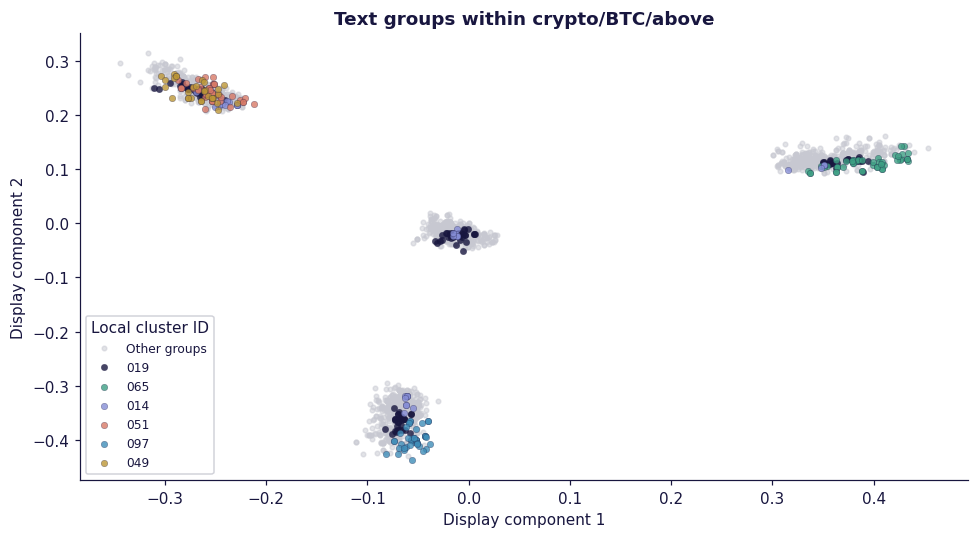

,cluster,title,yes_sub_title,similarity
181744,crypto/BTC/above/019,"Bitcoin price on Dec 12, 2024?","$99,550 or above",0.956047
181752,crypto/BTC/above/019,"Bitcoin price on Dec 12, 2024?","$99,550 or above",0.956047
148459,crypto/BTC/above/065,"Bitcoin price on Mar 9, 2025?","$77,750 or above",0.989058
153234,crypto/BTC/above/065,"Bitcoin price on Mar 7, 2025?","$77,750 or above",0.989058
113330,crypto/BTC/above/014,"Bitcoin price on Jun 5, 2025?","$105,000 or above",0.968855
113340,crypto/BTC/above/014,"Bitcoin price on Jun 5, 2025?","$105,000 or above",0.968855
148428,crypto/BTC/above/051,"Bitcoin price on Mar 9, 2025?","$81,000 or above",0.994218
148436,crypto/BTC/above/051,"Bitcoin price on Mar 9, 2025?","$81,000 or above",0.994218
148453,crypto/BTC/above/097,"Bitcoin price on Mar 9, 2025?","$79,250 or above",0.993576
148457,crypto/BTC/above/097,"Bitcoin price on Mar 9, 2025?","$78,250 or above",0.992469


In [221]:
assigned_train = assignments.query("split == 'train' and status == 'assigned'")
if assigned_train.empty:
    raise ValueError("No supported NLP groups; inspect coverage before continuing.")
example_family = assigned_train.family.value_counts().index[0]
family_rows = assigned_train[assigned_train.family.eq(example_family)]
example = family_rows.sample(min(2000, len(family_rows)), random_state=SEED)
projection = PCA(n_components=2, random_state=SEED).fit(vectors[family_rows.index])
xy = projection.transform(vectors[example.index])
top_groups = family_rows.cluster.value_counts().head(6).index

fig, ax = plt.subplots(figsize=(9, 5))
other = ~example.cluster.isin(top_groups).to_numpy()
ax.scatter(
    xy[other, 0],
    xy[other, 1],
    s=9,
    color=PALETTE["gray"],
    alpha=0.5,
    label="Other groups",
)
for cluster, color in zip(top_groups, CLUSTER_COLORS):
    mask = example.cluster.eq(cluster).to_numpy()
    ax.scatter(
        xy[mask, 0],
        xy[mask, 1],
        s=18,
        color=color,
        marker="o",
        edgecolors=PALETTE["navy"],
        linewidths=0.2,
        alpha=0.8,
        label=cluster.rsplit("/", 1)[-1],
    )
ax.set(
    title=f"Text groups within {example_family}",
    xlabel="Display component 1",
    ylabel="Display component 2",
)
ax.legend(title="Local cluster ID", fontsize=8)

show_figure("04_inside_a_family")
central_examples = []
for cluster in top_groups:
    members = family_rows[family_rows.cluster.eq(cluster)]
    central_examples.append(members.nlargest(2, "similarity"))
examples = pd.concat(central_examples)
example_columns = [
    "cluster",
    "title",
    "yes_sub_title",
    "similarity",
]
with pd.option_context("display.max_colwidth", 100):
    display(examples[example_columns])
examples[example_columns].to_csv(OUTPUT / "cluster_examples.csv", index=False)
del vectors

## 4. Build the prediction sample

Keep finalized binary YES/NO markets with at least $100 observed-window notional: `sum(count)` dollars, since complementary positions together cost $1 per unit. Check trade IDs and remove invalid prices, quantities, taker sides, and known combination products.

Summarize executions by contract and YES price, retaining execution count `n` as the weight. This preserves the weighted prediction objective without loading every trade into pandas. Executions from one contract still share its outcome.

Keep NLP clusters with **100 resolved training contracts and 20 training events**. All models use this same supported population, so the comparison does not cover every Kalshi market.

In [222]:
def quote(path: Path) -> str:
    return "'" + str(path.resolve()).replace("'", "''") + "'"


def extract(data: Path, assignments: Path, output: Path) -> tuple[pd.DataFrame, dict]:
    con = duckdb.connect()
    con.execute("SET threads=4")
    con.execute("SET memory_limit='3GB'")
    con.execute(f"SET temp_directory={quote(output / 'spill')}")

    con.execute(
        f"""
        CREATE VIEW markets AS
        SELECT *
        FROM read_csv(
            {quote(data / "master/markets.csv")},
            all_varchar=true
        )
    """,
    )
    con.execute(
        f"""
        CREATE VIEW assignments AS
        SELECT * FROM read_csv({quote(assignments)}, all_varchar=true)
    """,
    )

    for table in ["markets", "assignments"]:
        duplicates = con.sql(
            f"""
            SELECT count(*) - count(DISTINCT ticker) FROM {table}
        """,
        ).fetchone()[0]
        if duplicates:
            raise ValueError(f"Duplicate tickers in {table}")

    missing_markets = con.sql(
        """
        SELECT count(*)
        FROM assignments a
        LEFT JOIN markets m USING(ticker)
        WHERE m.ticker IS NULL
    """,
    ).fetchone()[0]
    if missing_markets:
        raise ValueError("Assignments contain tickers absent from master CSV")

    con.execute(
        f"""
        CREATE VIEW trades AS
        SELECT
            trade_id,
            ticker,
            taker_side,
            try_cast(yes_price AS BIGINT) p,
            try_cast(no_price AS BIGINT) np,
            try_cast(count AS BIGINT) units
        FROM read_csv(
            {quote(data / "master/trades.csv")},
            all_varchar=true
        )
    """,
    )

    counts = con.sql(
        """
        SELECT
            count(*),
            count(DISTINCT trade_id),
            count(*) FILTER(WHERE trade_id IS NULL OR trade_id=''),
            count(*) FILTER(WHERE
                p IS NULL OR np IS NULL OR units IS NULL
                OR p NOT BETWEEN 1 AND 99
                OR np NOT BETWEEN 1 AND 99
                OR p+np<>100 OR units<=0
                OR taker_side IS NULL
                OR taker_side NOT IN ('yes','no')
            )
        FROM trades
    """,
    ).fetchone()
    count_fields = [
        "raw_trades",
        "distinct_trade_ids",
        "missing_trade_ids",
        "invalid_trades",
    ]
    audit = dict(zip(count_fields, counts))
    if audit["missing_trade_ids"] or audit["raw_trades"] != audit["distinct_trade_ids"]:
        raise ValueError("Missing/duplicate trade IDs: reconcile before analysis")

    con.execute(
        """
        CREATE TEMP TABLE cells AS
        SELECT
            ticker,
            p,
            count(*)::BIGINT n,
            sum(units)::DOUBLE units
        FROM trades
        WHERE p BETWEEN 1 AND 99
            AND np BETWEEN 1 AND 99
            AND p+np=100
            AND units>0
            AND taker_side IN ('yes','no')
        GROUP BY ticker,p
    """,
    )
    con.execute(
        """
        CREATE TEMP TABLE eligible AS
        SELECT
            m.ticker,
            coalesce(nullif(m.event_ticker,''),m.ticker) event_id,
            CAST(m.result='yes' AS INTEGER) outcome,
            sum(c.units) AS notional_usd
        FROM markets m
        JOIN cells c USING(ticker)
        WHERE m.status='finalized'
            AND m.result IN ('yes','no')
            AND m.market_type='binary'
        GROUP BY ALL
        HAVING sum(c.units)>=100
    """,
    )

    audit["raw_markets"] = con.sql("SELECT count(*) FROM markets").fetchone()[0]
    audit["eligible_markets"] = con.sql("SELECT count(*) FROM eligible").fetchone()[0]
    audit["notional_definition"] = (
        "sum(count) dollars: complementary positions cost $1 per unit; observed CSV window only"
    )

    frame = con.sql(
        """
        SELECT
            c.*,
            e.event_id,
            e.outcome,
            e.notional_usd,
            coalesce(a.cluster,'') AS "cluster",
            coalesce(a.split,'not_in_assignments') split,
            coalesce(a.status,'not_in_assignments') assignment_status,
            coalesce(a.family,'') AS "family"
        FROM cells c
        JOIN eligible e USING(ticker)
        LEFT JOIN assignments a USING(ticker)
        ORDER BY c.ticker,c.p
    """,
    ).df()

    frame.to_csv(output / "sufficient_statistics.csv.gz", index=False)
    con.close()
    return frame, audit

In [223]:
def validate_splits(frame: pd.DataFrame) -> None:
    for column, message in [
        ("event_id", "Event leakage"),
        ("ticker", "Contract leakage"),
    ]:
        if frame.groupby(column).split.nunique().gt(1).any():
            raise ValueError(message)
    if not frame.split.isin(["train", "validation", "test"]).all():
        raise ValueError("Unknown split")


def combination_mask(contracts: pd.DataFrame) -> pd.Series:
    """Exclude known prefix combinations and explicit multi-award conjunctions.

    The inherited MVE prefix rule misses KXOSCARWINNERS combinations. The
    additional wording rule uses proposition structure, never outcomes/prices.
    It is conservative and is not a complete semantic combination detector.
    """
    return contracts.ticker.str.startswith(
        ("KXMVE", "MVE"),
    ) | contracts.title.str.contains(
        r"\bwin [^?]*,[^?]* at the Oscars\b",
        case=False,
        regex=True,
        na=False,
    )

,contracts,events,clusters,executions
split,,,,
train,158183,29753,286,32025333
validation,22942,4369,286,4434490
test,45619,8545,286,8991005


,audit
raw_trades,65017902
distinct_trade_ids,65017902
missing_trade_ids,0
invalid_trades,267291
raw_markets,529307
eligible_markets,351452
notional_definition,sum(count) dollars: complementary positions co...


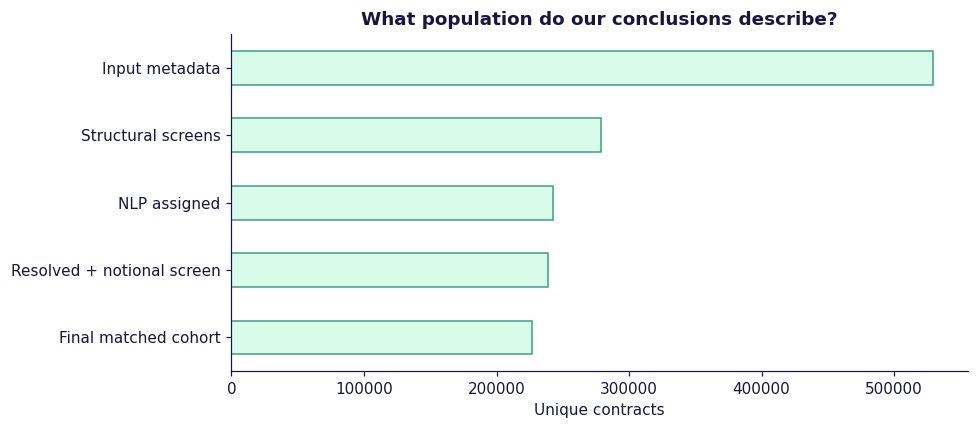

In [224]:
cells, audit = extract(DATA, ASSIGNMENTS, OUTPUT)
frame = cells[cells.assignment_status.eq("assigned") & cells.cluster.ne("")].copy()
resolved_assigned = frame.ticker.nunique()
excluded = contracts.loc[combination_mask(contracts), "ticker"]
frame = frame[~frame.ticker.isin(excluded)].copy()
support = (
    frame[frame.split.eq("train")]
    .groupby(
        "cluster",
    )
    .agg(
        contracts=("ticker", "nunique"),
        events=("event_id", "nunique"),
    )
)
supported = support.index[support.contracts.ge(100) & support.events.ge(20)]
frame = frame[frame.cluster.isin(supported)].reset_index(drop=True)
validate_splits(frame)
if set(frame.split) != set(SPLITS):
    raise ValueError("The prediction cohort needs all three splits.")
# Match outcomes and frozen group/split labels by unique contract ID.
labels = frame[
    [
        "ticker",
        "event_id",
        "split",
        "family",
        "cluster",
    ]
].drop_duplicates()
labels = labels.set_index("ticker", verify_integrity=True)
expected = assignments.set_index("ticker").rename(columns={"event_ticker": "event_id"})
if not labels.equals(expected.reindex(labels.index)[labels.columns]):
    raise ValueError("Cell labels disagree with CSV membership or assignments.")
frame["price"] = frame.p / 100
frame["residual"] = frame.outcome - frame.price
population = (
    frame.groupby("split")
    .agg(
        contracts=("ticker", "nunique"),
        events=("event_id", "nunique"),
        clusters=("cluster", "nunique"),
        executions=("n", "sum"),
    )
    .reindex(
        SPLITS,
    )
)
population.to_csv(OUTPUT / "population.csv")
(OUTPUT / "data_audit.json").write_text(json.dumps(audit, indent=2) + "\n")
display(population)
display(pd.Series(audit).to_frame("audit"))
attrition_counts = pd.Series(
    {
        "Input metadata": int(input_counts.sum()),
        "Structural screens": len(contracts),
        "NLP assigned": int(assignments.status.eq("assigned").sum()),
        "Resolved + notional screen": resolved_assigned,
        "Final matched cohort": frame.ticker.nunique(),
    },
)

fig, ax = plt.subplots(figsize=(9, 4))
attrition_counts.iloc[::-1].plot.barh(ax=ax, color=PALETTE["mint"], edgecolor=PALETTE["mint_dark"])
ax.set(
    title="What population do our conclusions describe?",
    xlabel="Unique contracts",
    ylabel="",
)

show_figure("05_population_funnel")
del cells, labels, expected

**Read the funnel:** bars count unique contracts remaining after each screen. The final bar is the common prediction sample; our conclusions apply to that population.

## 5. Becker's mispricing measure

Becker defines group mispricing as realized win rate minus average purchase-implied probability (2026, Section 3, Equation 1). We use YES price $p_i$ as a probability and outcome $y_i\in\{0,1\}$:

$$r_i=y_i-p_i, \qquad \delta_G=\frac{\sum_{i\in G}n_i r_i}{\sum_{i\in G}n_i}$$

A 30-cent contract settling YES has residual +0.70; settling NO gives −0.30. One residual does not establish mispricing. **Averaging residuals across comparable positions gives Becker's measure**; weighting summarized rows by `n` counts each execution once.

Positive group averages mean YES paid out more often than prices implied; negative averages mean less often. Multiply by 100 for percentage points. We study YES-side calibration, not returns on invested capital or Becker's maker/taker and equal-cost YES/NO decompositions.

The next plots use training data. The heatmap shows the eight families with the most training executions, hiding family/price cells with fewer than five training events.

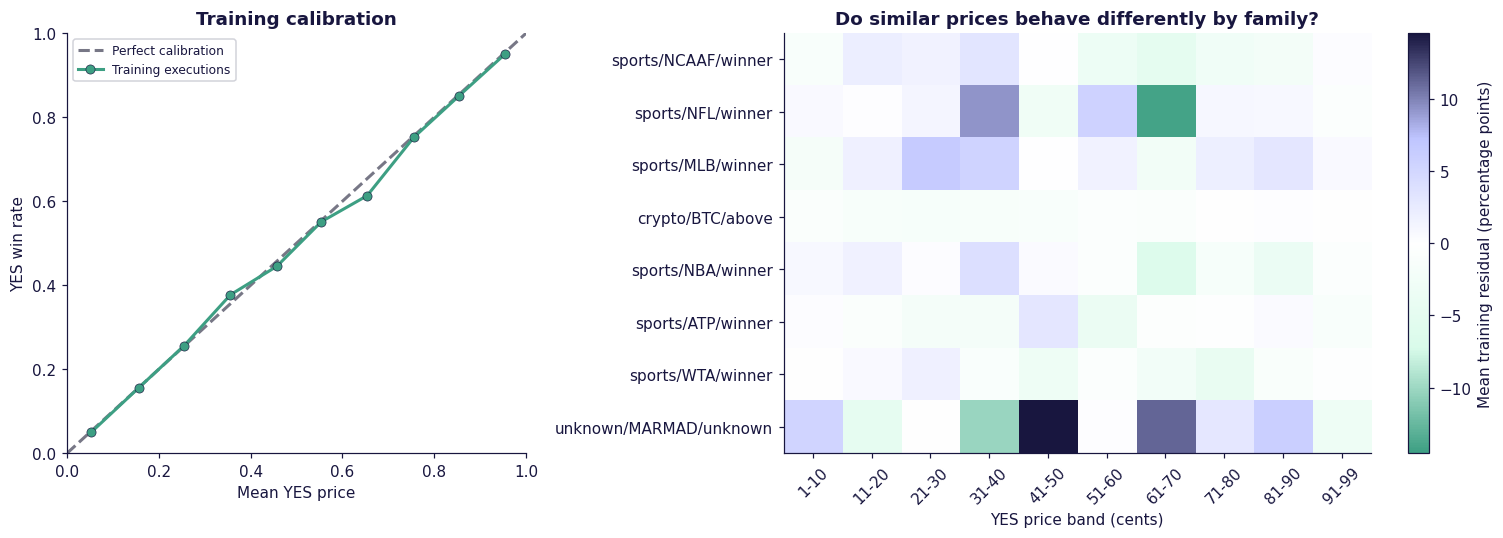

In [225]:
train = frame[frame.split.eq("train")].copy()
train["bucket"] = (train.p.astype(int) - 1) // 10
train["wins"] = train.n * train.outcome
train["price_total"] = train.n * train.price
train["residual_total"] = train.n * train.residual
calibration = train.groupby("bucket").agg(
    n=("n", "sum"),
    wins=("wins", "sum"),
    price_total=("price_total", "sum"),
)
calibration["mean_price"] = calibration.price_total / calibration.n
calibration["win_rate"] = calibration.wins / calibration.n
largest_families = train.groupby("family").n.sum().nlargest(8).index
family_bins = (
    train[train.family.isin(largest_families)]
    .groupby(
        ["family", "bucket"],
    )
    .agg(
        n=("n", "sum"),
        residual_total=("residual_total", "sum"),
        events=("event_id", "nunique"),
    )
)
family_bins["deviation_pp"] = 100 * family_bins.residual_total / family_bins.n
heat = (
    family_bins.deviation_pp.where(family_bins.events.ge(5))
    .unstack()
    .reindex(
        index=largest_families,
        columns=range(10),
    )
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
    gridspec_kw={"width_ratios": [1, 1.6]},
)
axes[0].plot(
    [0, 1],
    [0, 1],
    "--",
    color=PALETTE["gray_dark"],
    label="Perfect calibration",
)
axes[0].plot(
    calibration.mean_price,
    calibration.win_rate,
    "o-",
    color=PALETTE["mint_dark"],
    label="Training executions",
)
axes[0].set(
    title="Training calibration",
    xlabel="Mean YES price",
    ylabel="YES win rate",
)
axes[0].set(xlim=(0, 1), ylim=(0, 1))
axes[0].legend(fontsize=8)
limit = max(1, float(np.nanmax(np.abs(heat.to_numpy()))))
image = axes[1].imshow(
    heat,
    aspect="auto",
    cmap=DEVIATION_CMAP,
    norm=TwoSlopeNorm(
        vmin=-limit,
        vcenter=0,
        vmax=limit,
    ),
)
axes[1].set_xticks(
    range(10),
    [f"{10 * i + 1}-{min(99, 10 * i + 10)}" for i in range(10)],
    rotation=45,
)
axes[1].set_yticks(range(len(heat)), heat.index)
axes[1].set(
    title="Do similar prices behave differently by family?",
    xlabel="YES price band (cents)",
)
plt.colorbar(image, ax=axes[1], label="Mean training residual (percentage points)")

show_figure("06_training_calibration")

**Read the training plots:** points near the diagonal indicate calibration; above it means YES wins more often than prices imply. In the heatmap, lavender/navy means positive average residuals and mint means negative residuals. Compare families within a price column. These patterns motivate prediction but do not establish held-out performance.

## 6. Predict the residual

Use one shared ridge model per feature set, with fixed $\alpha=10$:

| Model | Features |
|---|---|
| Pooled | Price, price squared, price cubed |
| Structural | Price terms + one-hot family |
| Structural + NLP | Price terms + one-hot family + one-hot cluster |

Pooled is the main modeling baseline. Group indicators add constant offsets to a shared price curve; there are no separate group regressions or group-by-price interactions. Ridge limits coefficient size.

Fit weighted price scaling and category encoding on training data only. Indicators remain 0/1. Predict the residual and add it to price, clipping the resulting probability to [0, 1]. Market price is the zero-correction benchmark.

In [226]:
FEATURE_SETS = {
    "Pooled": [],
    "Structural": ["family"],
    "Structural + NLP": ["family", "cluster"],
}


def fit_comparisons(data: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Three feature ablations of one ridge estimator, all fitted on training labels only."""
    validate_splits(data)
    training = data[data.split.eq("train")]
    held = data[~data.split.eq("train")].copy().reset_index(drop=True)
    weights = training.n.to_numpy(dtype=float)
    residual = training.outcome.to_numpy() - training.price.to_numpy()

    numeric_train = training.price.to_numpy()[:, None] ** np.arange(1, 4)
    numeric_held = held.price.to_numpy()[:, None] ** np.arange(1, 4)
    scaler = StandardScaler().fit(numeric_train, sample_weight=weights)
    base_train = sparse.csr_matrix(scaler.transform(numeric_train))
    base_held = sparse.csr_matrix(scaler.transform(numeric_held))

    held["Market price"] = held.price
    dimensions = []
    for name, categories in FEATURE_SETS.items():
        x_train, x_held = base_train, base_held
        if categories:
            encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
            encoded_train = encoder.fit_transform(training[categories])
            encoded_held = encoder.transform(held[categories])
            x_train = sparse.hstack([base_train, encoded_train], format="csr")
            x_held = sparse.hstack([base_held, encoded_held], format="csr")

        model = Ridge(
            alpha=ALPHA,
            solver="lsqr",
            tol=1e-8,
        )
        model.fit(x_train, residual, sample_weight=weights / weights.mean())
        held[name] = np.clip(held.price.to_numpy() + model.predict(x_held), 0, 1)
        dimensions.append(
            {
                "approach": name,
                "features": x_train.shape[1],
                "training_cells": len(training),
                "shared_models": 1,
            },
        )
    return held, pd.DataFrame(dimensions)


with threadpool_limits(limits=2):
    predictions, model_sizes = fit_comparisons(frame)
display(model_sizes)
model_sizes.to_csv(OUTPUT / "model_sizes.csv", index=False)
predictions.to_parquet(OUTPUT / "heldout_predictions.parquet", index=False)

,approach,features,training_cells,shared_models
0,Pooled,3,3017654,1
1,Structural,95,3017654,1
2,Structural + NLP,381,3017654,1


### Inspect the corrections

The validation histograms use common bins and execution weights. Zero means no change to market price; +5 percentage points moves a 30% forecast to 35%. Wider distributions mean larger corrections, not necessarily better predictions. No outcomes enter this plot.

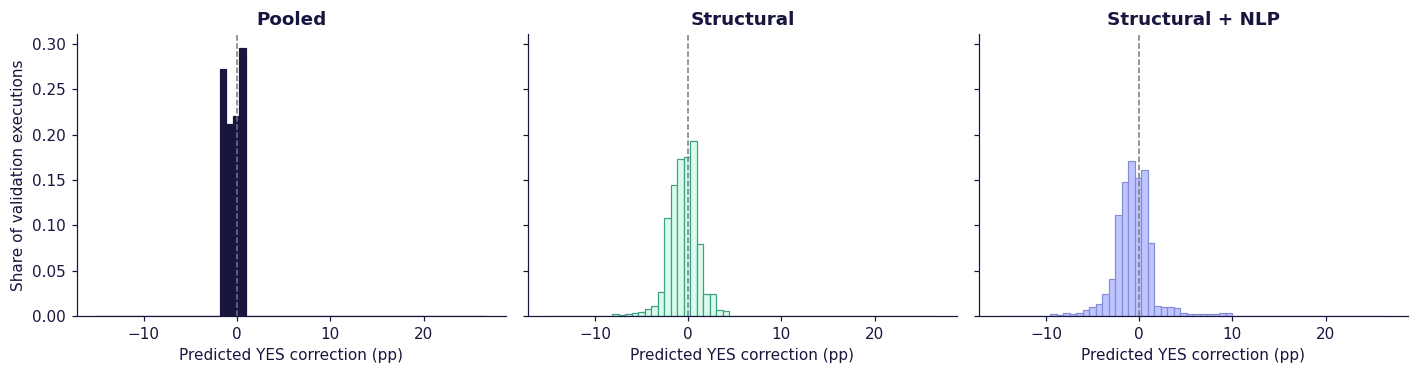

In [227]:
validation = predictions[predictions.split.eq("validation")]
corrections = 100 * validation[list(FEATURE_SETS)].sub(validation.price, axis=0)
common_bins = np.linspace(
    corrections.to_numpy().min(),
    corrections.to_numpy().max(),
    61,
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(13, 3.5),
    sharex=True,
    sharey=True,
)
for ax, name in zip(axes, FEATURE_SETS):
    correction = corrections[name]
    ax.hist(
        correction,
        bins=common_bins,
        weights=validation.n / validation.n.sum(),
        color=MODEL_FILLS[name],
        edgecolor=COLORS[name],
        linewidth=0.8,
    )
    ax.axvline(
        0,
        color=PALETTE["gray_dark"],
        linestyle="--",
        linewidth=1,
    )
    ax.set(title=name, xlabel="Predicted YES correction (pp)")
axes[0].set_ylabel("Share of validation executions")

show_figure("07_model_corrections")

## 7. Evaluate predictions

Use execution-weighted **Brier score**, where $q_i$ is the predicted YES probability and $\widehat r_i=q_i-p_i$:

$$\mathrm{Brier}=\frac{\sum_i n_i(y_i-q_i)^2}{\sum_i n_i}=\frac{\sum_i n_i(r_i-\widehat r_i)^2}{\sum_i n_i}$$

Brier evaluates residual predictions; it does not redefine mispricing. **Lower is better.** Score all approaches on identical observations, with test results as the main comparison.

In the score plot, left is better. The dashed line marks pooled, our modeling baseline; the dotted line marks uncorrected market price. A grouped model must beat pooled to show value from membership.

split,test,validation
approach,,
Market price,0.171318,0.169457
Pooled,0.171333,0.169913
Structural,0.171763,0.169833
Structural + NLP,0.171939,0.169859


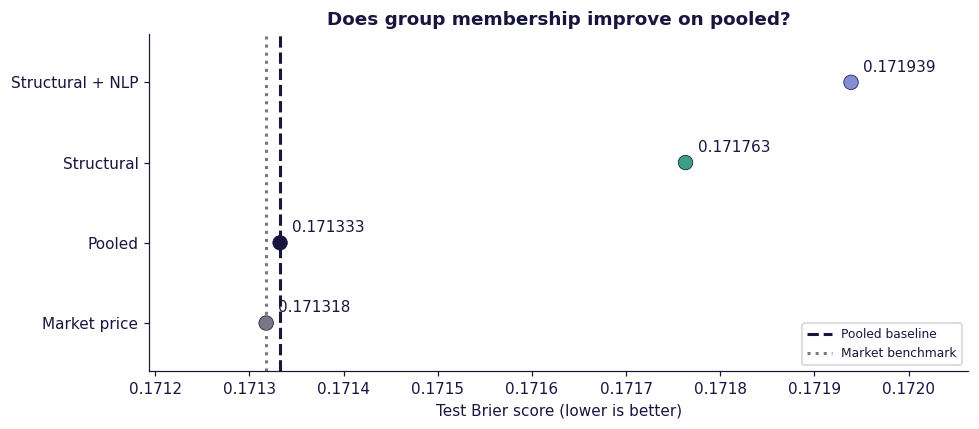

In [228]:
def brier(data, model):
    """Execution-weighted probability error, also residual MSE."""
    return np.average((data.outcome - data[model]) ** 2, weights=data.n)


score_rows = []
for split, held in predictions.groupby("split"):
    for name in COLORS:
        score_rows.append(
            {
                "split": split,
                "approach": name,
                "brier": brier(held, name),
            },
        )
scores = pd.DataFrame(score_rows)
scores.to_csv(OUTPUT / "scores.csv", index=False)
display(
    scores.pivot(
        index="approach",
        columns="split",
        values="brier",
    ).reindex(
        COLORS,
    ),
)
test_scores = scores[scores.split.eq("test")].set_index("approach").reindex(COLORS)

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(
    test_scores.brier,
    test_scores.index,
    s=90,
    c=[COLORS[n] for n in test_scores.index],
    edgecolors=PALETTE["navy"],
    linewidths=0.5,
)
for name, row in test_scores.iterrows():
    ax.annotate(
        f"{row.brier:.6f}",
        (row.brier, name),
        xytext=(8, 7),
        textcoords="offset points",
    )
ax.axvline(
    test_scores.at["Pooled", "brier"],
    color=COLORS["Pooled"],
    ls="--",
    label="Pooled baseline",
)
ax.axvline(
    test_scores.at["Market price", "brier"],
    color=COLORS["Market price"],
    ls=":",
    label="Market benchmark",
)
ax.legend(fontsize=8, loc="best")
ax.margins(x=0.2, y=0.2)
ax.set(
    title="Does group membership improve on pooled?",
    xlabel="Test Brier score (lower is better)",
)

show_figure("08_test_scores")

### Account for related trades

Bootstrap whole test events, keeping their executions together, for four paired comparisons:

- Structural vs pooled: value of structural membership.
- NLP vs pooled: total value of grouping.
- NLP vs structural: additional value of text grouping.
- Pooled vs market price: value of global recalibration.

**Read the intervals:** positive improvement favors the candidate. A 95% interval entirely above zero favors it; entirely below favors the baseline; crossing zero is inconclusive.

These are exploratory, unadjusted intervals conditional on fitted groups and models. They exclude refitting uncertainty and may miss dependence across different event IDs.

,candidate,baseline,improvement,ci_low,ci_high,events
0,Structural,Pooled,-0.000430,-0.000690,-0.000177,8545
1,Structural + NLP,Pooled,-0.000606,-0.000914,-0.000311,8545
2,Structural + NLP,Structural,-0.000176,-0.000357,0.000001,8545
3,Pooled,Market price,-0.000015,-0.000374,0.000362,8545


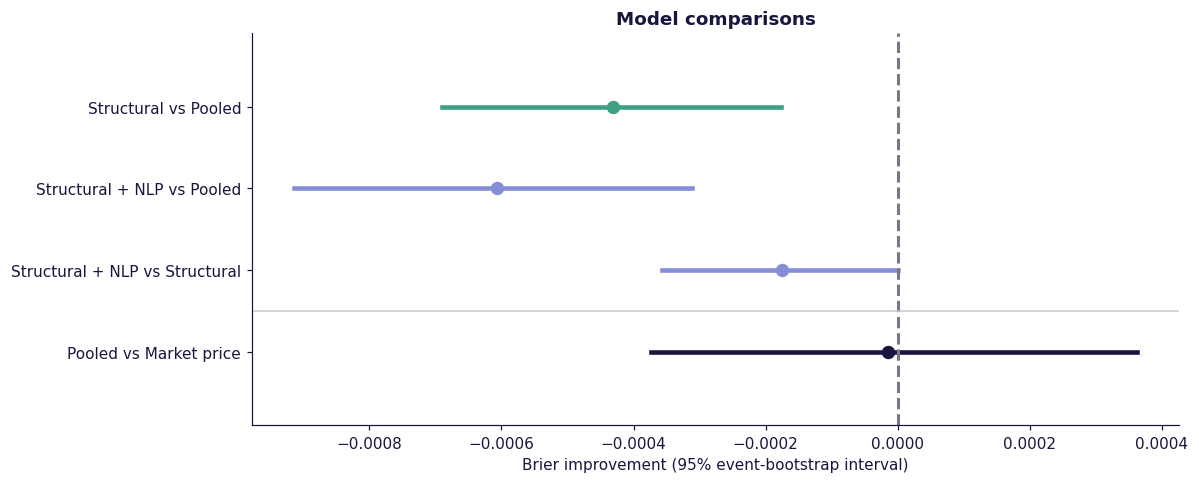

In [229]:
def compare_by_event(held: pd.DataFrame, candidate: str, baseline: str, repetitions: int) -> dict:
    """Bootstrap the paired loss difference using whole-event weighted totals."""
    baseline_error = (held.outcome - held[baseline]) ** 2
    candidate_error = (held.outcome - held[candidate]) ** 2
    difference = baseline_error - candidate_error
    blocks = (
        pd.DataFrame(
            {
                "event": held.event_id,
                "numerator": held.n * difference,
                "weight": held.n,
            },
        )
        .groupby(
            "event",
        )[["numerator", "weight"]]
        .sum()
        .to_numpy()
    )
    if len(blocks) < 2:
        raise ValueError("Need at least two held-out events for uncertainty.")
    rng = np.random.default_rng(SEED)
    draws = np.empty(repetitions)
    for i in range(repetitions):
        total = blocks[rng.integers(len(blocks), size=len(blocks))].sum(axis=0)
        draws[i] = total[0] / total[1]
    low, high = np.quantile(draws, [0.025, 0.975])
    return {
        "candidate": candidate,
        "baseline": baseline,
        "improvement": blocks[:, 0].sum() / blocks[:, 1].sum(),
        "ci_low": low,
        "ci_high": high,
        "events": len(blocks),
    }


test = predictions[predictions.split.eq("test")].copy()
pairs = [
    ("Structural", "Pooled"),
    ("Structural + NLP", "Pooled"),
    ("Structural + NLP", "Structural"),
    ("Pooled", "Market price"),
]
comparison_rows = []
for candidate, baseline in pairs:
    result = compare_by_event(
        test,
        candidate,
        baseline,
        BOOTSTRAP,
    )
    comparison_rows.append(result)
comparisons = pd.DataFrame(comparison_rows)
comparisons.to_csv(OUTPUT / "comparisons.csv", index=False)
display(comparisons)

fig, ax = plt.subplots(figsize=(11, 4.5))
for i, row in comparisons.iterrows():
    ax.plot(
        [row.ci_low, row.ci_high],
        [i, i],
        color=COLORS[row.candidate],
        linewidth=3,
    )
    ax.scatter(
        row.improvement,
        i,
        color=COLORS[row.candidate],
        s=60,
        zorder=3,
    )
ax.axvline(0, color=PALETTE["gray_dark"], linestyle="--")
ax.set_yticks(
    range(len(comparisons)),
    comparisons.candidate + " vs " + comparisons.baseline,
)
ax.axhline(2.5, color=PALETTE["gray"], linewidth=1)
ax.invert_yaxis()
ax.margins(y=0.3)
ax.set(
    title="Model comparisons",
    xlabel="Brier improvement (95% event-bootstrap interval)",
)

show_figure("09_incremental_value")

### Check the best-supported clusters

Rank eligible clusters by **distinct training events**, breaking ties by cluster ID. Evaluate existing predictions in the top 10, 25, and 50, plus all eligible clusters. No models are retrained, and test results do not select membership.

The left panel shows test execution coverage. The right shows improvement over pooled within each subset: above zero helps, below hurts. Subsets differ in topic and price mix, so compare paired improvements rather than raw scores. This descriptive check has no new significance tests and cannot establish sample size as the cause.

,training_clusters,min_training_events,test_clusters,test_contracts,test_events,test_execution_pct
subset,,,,,,
Top 10,10,502,10,7136,2137,35.395665
Top 25,25,314,25,14528,3551,41.488510
Top 50,50,257,50,18484,4458,49.482099
All eligible,286,20,286,45619,8545,100.000000


approach,Market price,Pooled,Structural,Structural + NLP
subset,,,,
Top 10,0.161751,0.162093,0.162295,0.162169
Top 25,0.161241,0.161610,0.161785,0.161693
Top 50,0.163662,0.163961,0.164128,0.164082
All eligible,0.171318,0.171333,0.171763,0.171939


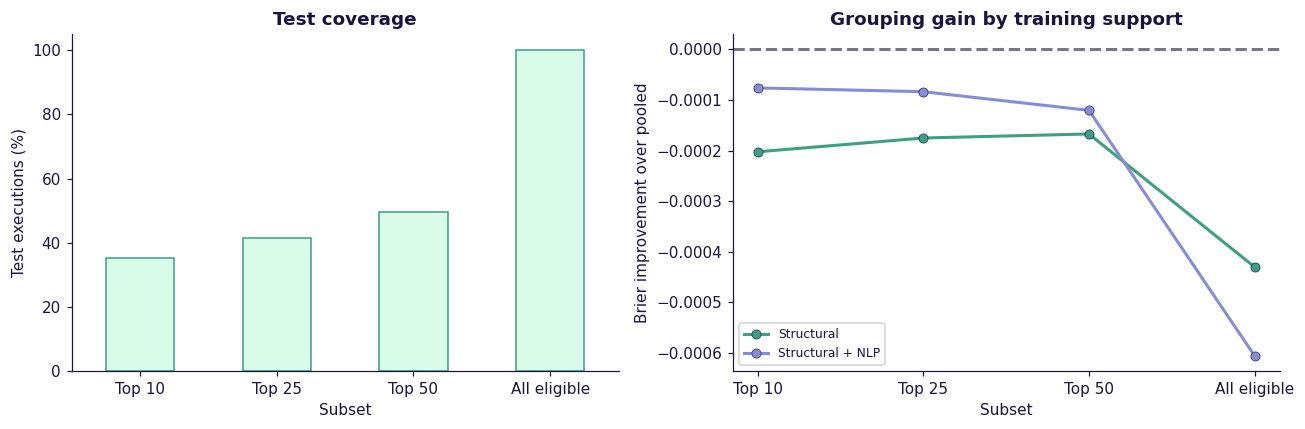

In [230]:
top_k_values = [10, 25, 50]
cluster_rank = (
    frame[frame.split.eq("train")]
    .groupby(
        "cluster",
    )
    .agg(
        training_events=("event_id", "nunique"),
        training_contracts=("ticker", "nunique"),
    )
    .reset_index()
    .sort_values(
        ["training_events", "cluster"],
        ascending=[False, True],
    )
)
cluster_rank.to_csv(OUTPUT / "cluster_training_support_ranked.csv", index=False)
subsets = [(f"Top {k}", k) for k in top_k_values] + [
    ("All eligible", len(cluster_rank)),
]
top_k_rows = []
for label, k in subsets:
    chosen = cluster_rank.head(k)
    subset = test[test.cluster.isin(chosen.cluster)]
    if subset.empty:
        continue
    pooled_brier = brier(subset, "Pooled")
    counts = {
        "training_clusters": len(chosen),
        "min_training_events": int(chosen.training_events.min()),
        "test_clusters": subset.cluster.nunique(),
        "test_contracts": subset.ticker.nunique(),
        "test_events": subset.event_id.nunique(),
        "executions": int(subset.n.sum()),
        "test_execution_pct": 100 * subset.n.sum() / test.n.sum(),
    }
    for name in COLORS:
        score = brier(subset, name)
        top_k_rows.append(
            {
                "subset": label,
                "approach": name,
                "brier": score,
                "improvement_vs_pooled": pooled_brier - score,
                **counts,
            },
        )
top_k_results = pd.DataFrame(top_k_rows)
top_k_results.to_csv(OUTPUT / "top_k_results.csv", index=False)
subset_order = [label for label, _ in subsets if label in top_k_results.subset.values]
top_k_coverage = top_k_results.drop_duplicates("subset").set_index("subset").reindex(subset_order)
display(
    top_k_coverage.drop(
        columns=[
            "approach",
            "brier",
            "improvement_vs_pooled",
            "executions",
        ],
    ),
)
score_table = top_k_results.pivot(
    index="subset",
    columns="approach",
    values="brier",
)
display(score_table.reindex(index=subset_order, columns=list(COLORS)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
top_k_coverage.test_execution_pct.plot.bar(
    ax=axes[0],
    color=PALETTE["mint"],
    edgecolor=PALETTE["mint_dark"],
    rot=0,
)
axes[0].set(
    title="Test coverage",
    xlabel="Subset",
    ylabel="Test executions (%)",
    ylim=(0, 105),
)
gains = top_k_results.pivot(
    index="subset",
    columns="approach",
    values="improvement_vs_pooled",
).reindex(
    subset_order,
)
for name in ["Structural", "Structural + NLP"]:
    axes[1].plot(
        range(len(subset_order)),
        gains[name],
        "o-",
        color=COLORS[name],
        label=name,
    )
axes[1].set_xticks(range(len(subset_order)), subset_order)
axes[1].axhline(0, color=PALETTE["gray_dark"], linestyle="--")
axes[1].set(
    title="Grouping gain by training support",
    xlabel="Subset",
    ylabel="Brier improvement over pooled",
)
axes[1].legend(fontsize=8)

show_figure("11_top_k_clusters")

## 8. Check calibration

The reliability plot compares mean predicted YES probabilities with observed win rates in prediction bins, weighted by executions. Above the diagonal means outcomes exceed predictions; below means the reverse.

Each model defines its own bins. Similar curves can hide Brier differences because binning averages individual errors. This is a visual check, not a model-selection rule.

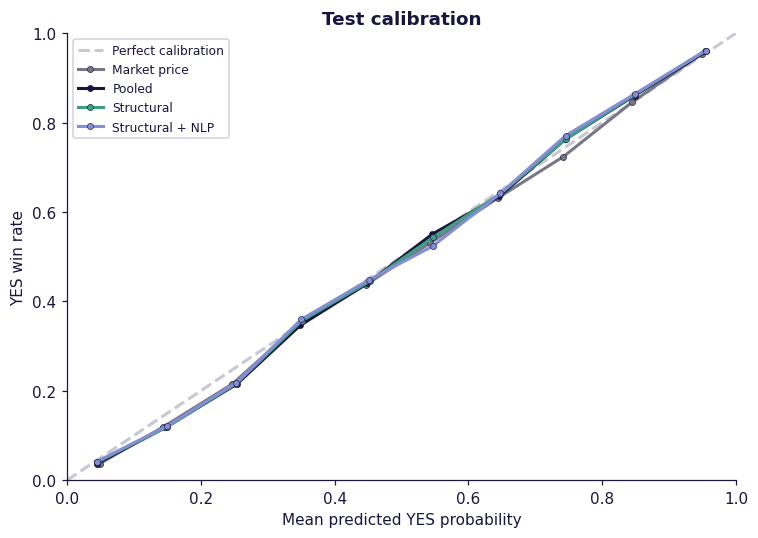

In [231]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(
    [0, 1],
    [0, 1],
    "--",
    color=PALETTE["gray"],
    label="Perfect calibration",
)
for name, color in COLORS.items():
    probability_bins = np.minimum((test[name] * 10).astype(int), 9)
    reliability = pd.DataFrame({"bin": probability_bins, "weight": test.n})
    reliability["predicted"] = test.n * test[name]
    reliability["observed"] = test.n * test.outcome
    reliability = reliability.groupby("bin")[["weight", "predicted", "observed"]].sum()
    rates = reliability[["predicted", "observed"]].div(reliability.weight, axis=0)
    ax.plot(
        rates.predicted,
        rates.observed,
        "o-",
        markersize=4,
        color=color,
        label=name,
    )
ax.set(
    title="Test calibration",
    xlabel="Mean predicted YES probability",
    ylabel="YES win rate",
)
ax.set(xlim=(0, 1), ylim=(0, 1))
ax.legend(fontsize=8)

show_figure("10_test_reliability")

## 9. Interpret the results

Compare grouped models with pooled, then NLP with structural. Use pooled versus market price as a separate benchmark check. Beating pooled would support using group membership, but would not automatically establish an improvement over market price.

The summary below is generated from this run. The top-K results describe where the models struggle; they do not establish significant subgroup differences.

In [232]:
conclusions = []
for heading, subset in [
    ("### Grouping comparisons", comparisons[comparisons.baseline.ne("Market price")]),
    (
        "### Separate market benchmark check",
        comparisons[comparisons.baseline.eq("Market price")],
    ),
]:
    conclusions.append(heading)
    for row in subset.itertuples(index=False):
        if row.ci_low > 0:
            interpretation = "interval above zero; candidate performs better"
        elif row.ci_high < 0:
            interpretation = "interval below zero; baseline performs better"
        else:
            interpretation = "interval includes zero; difference is inconclusive"
        conclusions.append(
            f"- **{row.candidate} versus {row.baseline}:** Brier improvement {row.improvement:+.6f}; {interpretation}.",
        )
    conclusions.append("")
display(Markdown("\n".join(conclusions)))
(OUTPUT / "conclusions.md").write_text("\n".join(conclusions) + "\n")

### Grouping comparisons
- **Structural versus Pooled:** Brier improvement -0.000430; interval below zero; baseline performs better.
- **Structural + NLP versus Pooled:** Brier improvement -0.000606; interval below zero; baseline performs better.
- **Structural + NLP versus Structural:** Brier improvement -0.000176; interval includes zero; difference is inconclusive.

### Separate market benchmark check
- **Pooled versus Market price:** Brier improvement -0.000015; interval includes zero; difference is inconclusive.


523

### Scope and limits

Our conclusion concerns these group features, this ridge model, and this sample. Poor predictive performance does not contradict Becker's historical mispricing finding or prove market efficiency: observing past deviations and predicting held-out deviations are different tasks.

Structural rules are heuristic, wording is a collected snapshot, and related outcomes may have different event IDs. This dataset informed earlier method revisions, so results remain exploratory. A stronger follow-up would freeze the method and use a later sample with verified training-label availability. We do not test a 72-hour forecast or trading profits after fees.

In [233]:
notebook_path = ROOT / "extension/notebooks/main.ipynb"
notebook = json.loads(notebook_path.read_text())
authored = [(c["cell_type"], "".join(c["source"])) for c in notebook["cells"]]
manifest = {
    "completed": True,
    "seed": SEED,
    "ridge_alpha": ALPHA,
    "bootstrap": BOOTSTRAP,
    "feature_sets": FEATURE_SETS,
    "comparison_pairs": pairs,
    "top_k_training_event_subsets": top_k_values,
    "grouping": vars(GROUPING),
    "chart_palette": PALETTE,
    "inputs": [
        {
            "path": str(p),
            "bytes": p.stat().st_size,
            "mtime_ns": p.stat().st_mtime_ns,
        }
        for p in required
    ],
    "versions": {
        p: version(p)
        for p in [
            "numpy",
            "pandas",
            "scipy",
            "scikit-learn",
            "duckdb",
            "matplotlib",
        ]
    },
    "notebook_sha256": hashlib.sha256(json.dumps(authored).encode()).hexdigest(),
    "elapsed_seconds": time.time() - started,
}
(OUTPUT / "run_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
print(
    f"Completed in {manifest['elapsed_seconds'] / 60:.1f} minutes. Tables, predictions, and 11 figures: {OUTPUT}",
)

Completed in 1.6 minutes. Tables, predictions, and 11 figures: /Users/colekvasnak/Documents/School/DS 340W/prediction-market-analysis/output/extension_notebook_simple
